<h3><center>Introduction to building a quant pricing library</center></h3>
<h1><center>Option Pricing by Partial Differential Equation using OOP</center></h1>
<h3><center>Abdulwahab, Animoku</center></h3>
<h4><center>28 October, 2026</center></h4>



## Option Pricing by PDE

<b>Goal of option pricing via PDE:<b>

* Use the Black Scholes PDE to price European Contract
* Use  different discretization scheme to achieve better results
* Compare the solution to the Analytical Pricer
* Price American Option with PDE method


<b>Extension<b>
* Calculate Greeks based on the different Schemes
* Extend PDE pricing scheme to Forward<b>

# Steps to achieve our Objectives
* Create Market Model
* Create European Contract using market inputs (underlying, Call/Put, Long/Short, strike, expiry)
* Create PDEParams using $dS, dt, S_{min_{multiplier}}, S_{max_{multiplier}} $ and method (implicit, explicit, CrankNicolson) as inputs
* Create EuropeanPDEPricer using the contract, model and PDEParams
* Calculate FV
* Visualize the Call and Put prices in 2D

In [1]:
import matplotlib.pyplot as plt

to_plot = [ {'data': [[0]*6, list(range(6))],
             'color':'r',
             'title':'Our interests'},
           {'data': [list(range(6))+[5]*6+list(range(6)), [0]*6+list(range(6))+[5]*6],
            'color' : 'g',
            'title' : 'Boundary and initial conditions'
           },] + [
           {'data': [[i]*6, list(range(6))],
            'color' : 'g',
            'title' : f'Step {5-i}'
           } for i in range(4,-1,-1)]
           

def my_illustration_plot(to_plot):
    fig,ax = plt.subplots(1)
    for x in to_plot:
        plt.scatter(*x['data'], s=300, c=x['color'])
        plt.title(x['title'])
#         plt.axis('on')
        plt.xlim(-1,6)
    ax.set_xticks([])
    ax.set_yticks([])
    plt.xlabel("Time")
    plt.ylabel("Stock")
    plt.show()
    

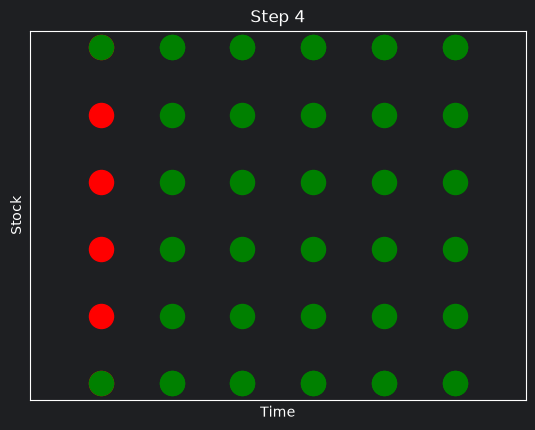

In [2]:
my_illustration_plot(to_plot[:6])

## Call and Put Option Pricing for European Options via PDE

Recall that the value $V$ of a Europoean option at time $t$, written on an underlying asset with price $S,$ satisfies the Black-Scholes equation
  $$ \frac{\delta V}{\delta t} + \frac{1}{2}\sigma^2 S^2\frac{\delta V^2}{\delta S^2} + rS \frac{\delta V}{\delta S} - rV =0,$$
 
with suitable terminal and boundary conditions:
$$V_C(S,T) = \max \{S-K,0 \}$$
$$V_P(S,T) = \max \{K-S,0 \}.$$
$$V_C(S_{\min}, t) = 0, V_C(S_{\max}, t) = S_{\max}- Ke^{-r(T-t)}, $$
$$V_P(S_{\max}, t) = 0, V_P(S_{\min}, t) = Ke^{-r(T-t)}-S_{\min}. $$

In [4]:
import sys
from pathlib import Path

sys.path.insert(0, "/Users/marija/QuantCourseBP")
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from src.enums import *
from src.utils import *
from src.market_data import *
from src.pricer import *
# Make charts interactive
%matplotlib notebook

# Initialize market data
MarketData.initialize()

QuantCourseBP f5416f667ee89363124e80786f30ec55b209a448*


# Utility function

In [5]:
"""The pricing function of European call option"""
def black_scholes_eur_call(spot, time_to_mat,sigma, strike, rate):
    d1_vec = ( np.log( spot / strike ) + ( rate + 0.5 * sigma**2 ) * time_to_mat ) / ( sigma * time_to_mat**0.5 )
    d2_vec = d1_vec - sigma * time_to_mat**0.5

    N_d1_vec = norm.cdf(d1_vec)
    N_d2_vec = norm.cdf(d2_vec)

    return N_d1_vec * spot - strike * np.exp((-1.0)*rate*time_to_mat) * N_d2_vec

# Create Test Example Contracts

In [6]:
und = Stock.TEST_COMPANY
expiry = 2.0
strike = 0.95 * MarketData.get_spot()[und]
ls = LongShort.LONG

In [7]:
derivative_type = [PutCallFwd.CALL, PutCallFwd.PUT]
model_types = [BSVolModel(und), FlatVolModel(und)]

contracts=[EuropeanContract(und, deriv_type, ls, strike, expiry) for deriv_type in derivative_type]
analytic_pricer = [EuropeanAnalyticPricer(contract, model_type, Params()) for contract in contracts for model_type in model_types]
analytical_fv= [pricer.calc_fair_value() for pricer in analytic_pricer]

print(f"FairValues:{analytical_fv}")

FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


# Example with Explicit Method

* Create European Contract
* Create Market Model
* Create PDEParam
* Create EuropeanPDEPricer
* Calculate FV based on Explicit method
* Visualize the Call or Put prices in 2D 

In [8]:
params_exp = PDEParams(method = BSPDEMethod.EXPLICIT)

pde_exp_pricer = [EuropeanPDEPricer(contract, model_type, params_exp) for contract in contracts for model_type in model_types]
pde_exp_fv= [pricer.calc_fair_value() for pricer in pde_exp_pricer]

# pde_exp_pricer = [GenericPDEPricer(contract, model_type, params_exp) for contract in contracts for model_type in model_types]
# pde_exp_fv= [pricer.calc_fair_value() for pricer in pde_exp_pricer]


In [9]:
print(f"PDE Explicit method FairValues:{pde_exp_fv}")
print(f"Analytical method FairValues:{analytical_fv}")

PDE Explicit method FairValues:[np.float64(23.604447307816308), np.float64(19.559315913934707), np.float64(9.563828924282564), np.float64(5.518692809208318)]
Analytical method FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


In [10]:
Errors = [f"{(price1-price2)/price1 *100:.4f}%" for price1, price2 in zip(pde_exp_fv, analytical_fv)]
print(f"Error between the Analytical and PDE Explicit method FairValues:{Errors}")

Error between the Analytical and PDE Explicit method FairValues:['-0.0077%', '0.0018%', '-0.0209%', '0.0031%']


# Attributes needed to create visualization

In [11]:
und_step = pde_exp_pricer[0].und_step
time_step = pde_exp_pricer[0].time_step
s_min= pde_exp_pricer[0].stock_min
s_max=pde_exp_pricer[0].stock_max
sigma = pde_exp_pricer[0].bsPDE.sigma
spot = pde_exp_pricer[0].initial_spot
rate = pde_exp_pricer[0].interest_rate
num_of_und_steps = pde_exp_pricer[0].bsPDE.num_of_und_steps

# Plot the graph for the first contract for different S values

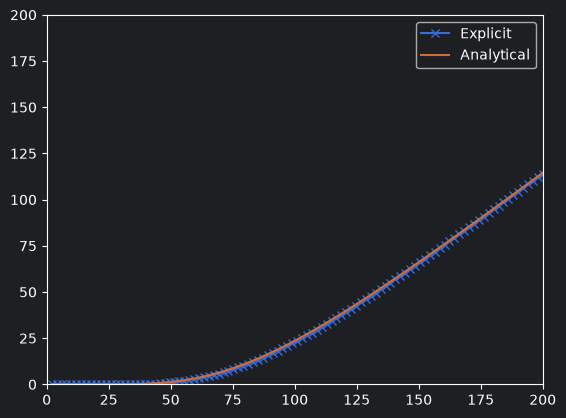

In [12]:
import matplotlib.pyplot as plt
sol_exp = pde_exp_pricer[0].grid[:,1]
Spots = np.linspace(s_min + und_step, s_max, num_of_und_steps+1)

%matplotlib inline
plt.plot(Spots, sol_exp, "x-", label="Explicit")
plt.plot(Spots, black_scholes_eur_call(Spots, expiry, sigma, strike, rate), label="Analytical")

plt.xlim(0, s_max)
plt.ylim(0,s_max)
plt.legend()
plt.show()

# Example with Non-Convergence with Explicit Params

In [13]:
params_exp = PDEParams(und_step = 0.01, time_step=0.001, method = BSPDEMethod.EXPLICIT)

pde_exp_pricer = EuropeanPDEPricer(contracts[0], model_types[0], params_exp) 
pde_exp_fv= pde_exp_pricer.calc_fair_value()


/Users/marija/QuantCourseBP/src/numerical_method.py:177: RuntimeWarning: overflow encountered in scalar add
  self.grid[i, j] = alpha[i] * self.grid[i - 1, j + 1] + beta[i] * self.grid[i, j + 1] + gamma[i] \
/Users/marija/QuantCourseBP/src/numerical_method.py:177: RuntimeWarning: overflow encountered in scalar multiply
  self.grid[i, j] = alpha[i] * self.grid[i - 1, j + 1] + beta[i] * self.grid[i, j + 1] + gamma[i] \
/Users/marija/QuantCourseBP/src/numerical_method.py:177: RuntimeWarning: invalid value encountered in scalar add
  self.grid[i, j] = alpha[i] * self.grid[i - 1, j + 1] + beta[i] * self.grid[i, j + 1] + gamma[i] \


In [14]:
print(f"PDE Explicit method FairValues:{pde_exp_fv}")

PDE Explicit method FairValues:nan


# Example with Implicit Method

* Create European Contract
* Create Market Model
* Create PDEParams
* Create EuropeanPDEPricer
* Calculate FV based on Implicit method
* Visualize the Call or Put prices in 2D

In [15]:
param_imp = PDEParams(method = BSPDEMethod.IMPLICIT)

pde_imp_pricer = [EuropeanPDEPricer(contract, model_type, param_imp) for contract in contracts for model_type in model_types]
pde_imp_fv= [pricer.calc_fair_value() for pricer in pde_imp_pricer]

In [16]:
print(f"PDE Implicit method FairValues:{pde_imp_fv}")
print(f"Analytical method FairValues:{analytical_fv}")

PDE Implicit method FairValues:[np.float64(23.60198913553244), np.float64(19.557755216197776), np.float64(9.562097627250253), np.float64(5.517605239203791)]
Analytical method FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


In [17]:
Errors_imp = [f"{(price1-price2)/price1 *100:.4f}%" for price1, price2 in zip(pde_imp_fv,analytical_fv)]
print(f"Error between the Analytical and PDE Explicit method FairValues:{Errors_imp}")

Error between the Analytical and PDE Explicit method FairValues:['-0.0182%', '-0.0062%', '-0.0390%', '-0.0166%']


# Compare Implicit Method with Analytical Pricer

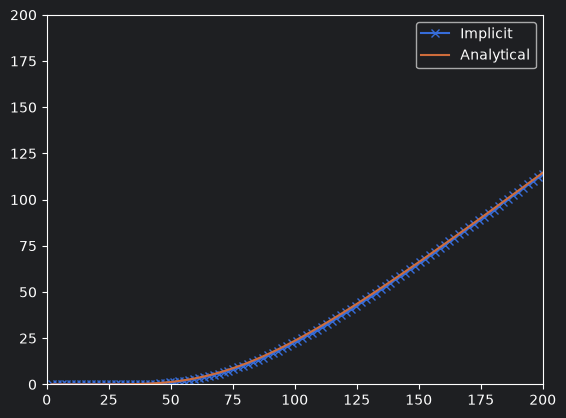

In [18]:
sol_imp = pde_imp_pricer[0].grid[:,1]


plt.plot(Spots, sol_imp, "x-", label="Implicit")
plt.plot(Spots, black_scholes_eur_call(Spots, expiry, sigma, strike, rate), label="Analytical")

plt.xlim(0, s_max)
plt.ylim(0,s_max)
plt.legend()
plt.show()

# Example with Crank Nicolson Method

* Create European Contract
* Create Market Model
* Create PDEParams
* Create GenericPDEPricer
* Calculate FV and Greeks based on Crank_Nicolson methods
* Visualize the Call and Put prices in 2D and 3D

In [19]:
param_crn = PDEParams(method = BSPDEMethod.CRANK_NICOLSON)

pde_crn_pricer = [EuropeanPDEPricer(contract, model_type, param_crn) for contract in contracts for model_type in model_types]
pde_crn_fv= [pricer.calc_fair_value() for pricer in pde_crn_pricer]


In [20]:
print(f"PDE Crank-Nicolson method FairValues:{pde_crn_fv}")
print(f"Analytical method FairValues:{analytical_fv}")

PDE Crank-Nicolson method FairValues:[np.float64(23.60340863403569), np.float64(19.558594355475947), np.float64(9.562963346249724), np.float64(5.518149067657555)]
Analytical method FairValues:[np.float64(23.60627624868423), np.float64(19.558965822125977), np.float64(9.565830962100371), np.float64(5.518520535542123)]


In [21]:
Errors_crn = [f"{(price1-price2)/price1 *100:.4f}%" for price1, price2 in zip(pde_crn_fv,analytical_fv)]
print(f"Error between the Analytical and PDE Crank Nicolson method FairValues:{Errors_crn}")

Error between the Analytical and PDE Crank Nicolson method FairValues:['-0.0121%', '-0.0019%', '-0.0300%', '-0.0067%']


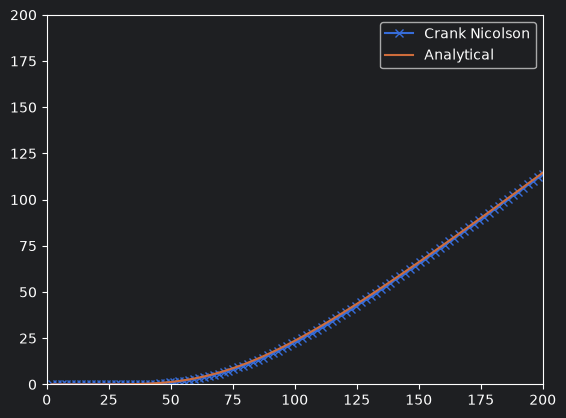

In [22]:
sol_imp = pde_crn_pricer[0].grid[:,1]

plt.plot(Spots, sol_imp, "x-", label="Crank Nicolson")
plt.plot(Spots, black_scholes_eur_call(Spots, expiry, sigma, strike, rate), label="Analytical")

plt.xlim(0, s_max)
plt.ylim(0,s_max)
plt.legend()
plt.show()

# Pricing American Option with Black Scholes PDE

<b>Properties of American Option:<b>
* The price of an American Option is atleast as much as the European Option with the same properties:
  $V_t^{am} \geq V_t^{eur}, \ for \, any\, \;  t \in [0,T]$
* An American option has at least the value of the payoff at any time $t.$
* There are different numerical techniques to price an American Option: LongStaff-Schwarz, PDE, Tree methods 
* American Call contract will never be exercised early unless the stock has a dividend.
* For a sufficient Low Price an American Put will be exercised

<b>Consider the Porfolio:<b>
* Consider an American put has a value lower than $(K-S)^+$
Strategy:
* Take Long positions in both the Asset and in the money Put Option
* Exercise the Put option immediately and sell the stock at higher price K. 
* This creates an arbitrage opportunity until the Put price becomes at least the payoff.
* Thus,
$$V_{t,c}^{am} \geq \max(S_t - K,0), \ for \, any\, \;  t \in [0,T]$$
$$V_{t,p}^{am} \geq \max(K- S_t,0), \ for \, any\, \;  t \in [0,T]$$

In [23]:
params_exp = PDEParams(method = BSPDEMethod.CRANK_NICOLSON)
contracts=[AmericanContract(und, deriv_type, ls, strike, expiry) for deriv_type in derivative_type]

pde_exp_pricer = [AmericanPDEPricer(contract, model_type, params_exp) for contract in contracts for model_type in model_types]
pde_exp_fv= [pricer.calc_fair_value() for pricer in pde_exp_pricer]

In [24]:
model_types

In [25]:
print(f"PDE Explicit method FairValues:{pde_exp_fv}")

PDE Explicit method FairValues:[np.float64(23.60340863403569), np.float64(19.558594355475947), np.float64(10.449941938430383), np.float64(6.280381151300373)]


# Conclusion

* We have seen the implemention of European Call/Put options pricing via PDE methods
* Which method is faster?

<b> Project Ideas <b>

* Implement Forward pricing on the Grid
* Implement the Greeks using the bump and re-evaluation method

# Homework 5 — Pricing the Maximum of Two Stocks

## Part (a): Analytical fair value

Assume both stocks follow geometric Brownian motion with constant volatility $\sigma$, no dividends, and independent Brownian motions.

Under the risk-neutral measure, $$ dS_i(t)=rS_i(t)\,dt+\sigma S_i(t)\,dW_i(t), \qquad i=1,2,$$
where $dW_1\,dW_2=0$.

The terminal payoff is
$$
V(T)=\max(S_1(T),S_2(T)).
$$

Therefore, the fair value at time zero is
$$
V_0=e^{-rT}\mathbb{E}^{\mathbb Q}
[\max(S_1(T),S_2(T))].
$$

We can rewrite the payoff as
$$
\max(S_1(T),S_2(T))
=S_2(T)+(S_1(T)-S_2(T))^+.
$$

Thus, the contract is equivalent to holding the second stock plus
an option to exchange the second stock for the first.

By the exchange-option formula,
$$
V_0=S_1(0)\Phi(d_1)+S_2(0)\Phi(-d_2),
$$
where $\Phi$ is the standard normal cumulative distribution function,
$$
d_1=
\frac{\ln(S_1(0)/S_2(0))+\frac12\sigma_{\mathrm{ex}}^2T}
{\sigma_{\mathrm{ex}}\sqrt{T}},
\qquad
d_2=d_1-\sigma_{\mathrm{ex}}\sqrt{T}.
$$

Since the stocks are independent and have equal volatility,
$$
\sigma_{\mathrm{ex}}
=\sqrt{\sigma^2+\sigma^2}
=\sqrt{2}\sigma.
$$

For $S_1(0)=S_2(0)=100$, this simplifies to
$$
\boxed{V_0=200\Phi\left(\sigma\sqrt{\frac{T}{2}}\right).}
$$

The interest rate cancels because the discounted stock prices
have a joint distribution independent of $r$ under these assumptions. I will use this formula to calculate the value
in Python.

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


#Initial prices specified in the assignment
S1 = 100.0
S2 = 100.0

#Example parameters used throughout parts (a)–(d)
sigma = 0.25
r = 0.03
T = 1.0


def maximum_stock_price(s1, s2, sigma, maturity):
    """Analytical value for independent stocks with equal volatility."""
    if maturity == 0 or sigma == 0:
        return max(s1, s2)

    total_vol = np.sqrt(2.0) * sigma * np.sqrt(maturity)
    d1 = np.log(s1 / s2) / total_vol + 0.5 * total_vol
    d2 = d1 - total_vol

    return s1 * norm.cdf(d1) + s2 * norm.cdf(-d2)


analytical_price = maximum_stock_price(S1, S2, sigma, T)

print(f"Analytical fair value: {analytical_price:.6f}")

Analytical fair value: 114.031620


## Part (b): Derivation of the pricing PDE

Under the risk-neutral measure, the stock prices satisfy
$$
dS_1=rS_1\,dt+\sigma S_1\,dW_1,
\qquad
dS_2=rS_2\,dt+\sigma S_2\,dW_2.
$$

The Brownian motions are independent, so
$$
dW_1\,dW_2=0.
$$

Let $V(t,s_1,s_2)$ denote the contract value. Applying the
two-dimensional Itô formula gives
$$
\begin{aligned}
dV={}&\left(
V_t+rs_1V_{s_1}+rs_2V_{s_2}
+\frac12\sigma^2s_1^2V_{s_1s_1}
+\frac12\sigma^2s_2^2V_{s_2s_2}
\right)dt\\
&+\sigma s_1V_{s_1}\,dW_1
+\sigma s_2V_{s_2}\,dW_2.
\end{aligned}
$$

There is no mixed derivative term because the stock processes are independent.

The discounted contract value $e^{-rt}V(t,S_1(t),S_2(t))$
must be a martingale. Its drift is therefore zero, giving
$$
\boxed{
V_t
+\frac12\sigma^2s_1^2V_{s_1s_1}
+\frac12\sigma^2s_2^2V_{s_2s_2}
+rs_1V_{s_1}+rs_2V_{s_2}
-rV=0.
}
$$

The terminal condition is
$$
V(T,s_1,s_2)=\max(s_1,s_2).
$$

At the lower boundaries, a stock starting at zero remains zero.
With no dividends, the value of receiving the other stock at
maturity equals its current price. Thus,
$$
V(t,0,s_2)=s_2,
\qquad
V(t,s_1,0)=s_1.
$$

For the numerical solution, we must also specify boundary
conditions at the upper edges of the truncated stock-price domain.
This is the two-dimensional Black–Scholes PDE for two independent,
non-dividend-paying stocks with equal volatility.

## Part (c): Finite difference solution

I solve the two-dimensional Black–Scholes PDE using an explicit
finite difference method.

I introduce time to maturity, $\tau=T-t$, and write
$U(\tau,s_1,s_2)=V(T-\tau,s_1,s_2)$. The PDE becomes
$$
U_\tau=
\frac12\sigma^2s_1^2U_{s_1s_1}
+\frac12\sigma^2s_2^2U_{s_2s_2}
+rs_1U_{s_1}+rs_2U_{s_2}-rU.
$$

I start from the terminal payoff,
$$
U(0,s_1,s_2)=\max(s_1,s_2),
$$
and advance from $\tau=0$ to $\tau=T$.

### Discretization

I use a uniform grid in both stock prices. I approximate the
first and second derivatives by central differences:
$$
U_{s_1}\approx
\frac{U_{i+1,j}-U_{i-1,j}}{2h},
\qquad
U_{s_1s_1}\approx
\frac{U_{i+1,j}-2U_{i,j}+U_{i-1,j}}{h^2},
$$
with analogous expressions for the second stock.

At each time step, I update the interior values using
$$
U^{n+1}_{i,j}=U^n_{i,j}
+\Delta\tau\,L_hU^n_{i,j},
$$
where $L_h$ is the finite difference approximation of the
spatial operator above.

### Boundary conditions and stability

At the lower boundaries, I impose
$$
U(\tau,0,s_2)=s_2,
\qquad U(\tau,s_1,0)=s_1.
$$

I truncate both stock-price axes at $S_{\max}=400$.
At the upper boundaries, I approximate the value as linear
in the outward stock-price direction. For example,
$$
U_{N-1,j}=2U_{N-2,j}-U_{N-3,j}.
$$
These are approximate boundary conditions on a finite domain.

I choose the time step so that the interior central coefficient
remains positive:
$$
\Delta\tau\left[
2\sigma^2(N-2)^2+r
\right]\leq0.9,
$$
where $N$ is the number of grid points on each stock-price axis.
For my chosen parameters, the neighbouring coefficients are
also nonnegative.

Finally, I compare the computed price at $(100,100)$ with the
analytical value from part (a).

In [30]:
# Part (c): Explicit finite difference method

def solve_maximum_fdm(sigma, r, T, Smax=400.0, N=121):
    stock = np.linspace(0.0, Smax, N)
    h = stock[1] - stock[0]

    X, Y = np.meshgrid(stock, stock, indexing="ij")

    # Initial condition in time to maturity
    V = np.maximum(X, Y)

    # Interior stock prices
    x = X[1:-1, 1:-1]
    y = Y[1:-1, 1:-1]

    # Choose a sufficiently small explicit time step
    time_steps = max(
        1,
        int(np.ceil(T * (2 * sigma**2 * (N - 2)**2 + r) / 0.9))
    )
    dt = T / time_steps

    # Check nonnegative neighbouring coefficients
    indices = np.arange(1, N - 1)
    if np.any(sigma**2 * indices**2 < abs(r) * indices):
        raise ValueError(
            "The central-difference neighbour coefficients "
            "are negative for these parameters."
        )

    for _ in range(time_steps):
        middle = V[1:-1, 1:-1]

        # First derivatives
        d1 = (V[2:, 1:-1] - V[:-2, 1:-1]) / (2 * h)
        d2 = (V[1:-1, 2:] - V[1:-1, :-2]) / (2 * h)

        # Second derivatives
        d11 = (
            V[2:, 1:-1] - 2 * middle + V[:-2, 1:-1]
        ) / h**2

        d22 = (
            V[1:-1, 2:] - 2 * middle + V[1:-1, :-2]
        ) / h**2

        change = (
            0.5 * sigma**2 * (x**2 * d11 + y**2 * d22)
            + r * (x * d1 + y * d2)
            - r * middle
        )

        V_new = V.copy()
        V_new[1:-1, 1:-1] = middle + dt * change

        # Exact lower boundary conditions
        V_new[0, :] = stock
        V_new[:, 0] = stock

        # Linear extrapolation at the upper boundaries
        V_new[-1, 1:-1] = (
            2 * V_new[-2, 1:-1] - V_new[-3, 1:-1]
        )
        V_new[1:-1, -1] = (
            2 * V_new[1:-1, -2] - V_new[1:-1, -3]
        )

        # Average the extrapolations at the upper corner
        V_new[-1, -1] = 0.5 * (
            2 * V_new[-2, -1] - V_new[-3, -1]
            + 2 * V_new[-1, -2] - V_new[-1, -3]
        )

        V = V_new

    if not np.isfinite(V).all():
        raise RuntimeError("The finite difference solution overflowed.")

    return stock, V, time_steps


stock_grid, fdm_values, time_steps = solve_maximum_fdm(
    sigma, r, T
)

# Interpolate along each stock-price direction
values_at_S1 = np.array([
    np.interp(S1, stock_grid, fdm_values[:, j])
    for j in range(len(stock_grid))
])

fdm_price = np.interp(S2, stock_grid, values_at_S1)

print(f"Time steps:       {time_steps}")
print(f"Analytical price: {analytical_price:.6f}")
print(f"FDM price:        {fdm_price:.6f}")
print(f"Absolute error:   {abs(fdm_price - analytical_price):.6f}")

Time steps:       1967
Analytical price: 114.031620
FDM price:        114.017100
Absolute error:   0.014521


### Grid convergence

I repeat the calculation with finer stock-price grids, reducing
the time step automatically to maintain the interior stability
condition. I compare each result with the analytical price.

I keep the initial stock prices exactly on the grids so that
interpolation does not affect this comparison.

Grid points | Spacing | Time steps | FDM price  | Absolute error
--------------------------------------------------------------------
         41 |  10.000 |        212 | 113.899588 | 0.132032
         61 |   6.667 |        484 | 113.973336 | 0.058285
         81 |   5.000 |        867 | 113.998906 | 0.032715
        121 |   3.333 |       1967 | 114.017100 | 0.014521


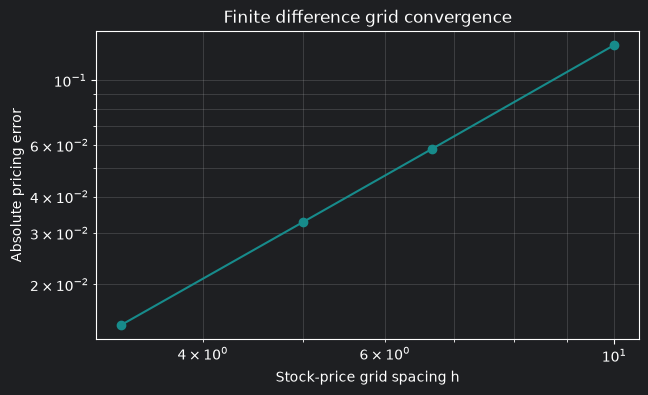

In [31]:
grid_sizes = [41, 61, 81, 121]
convergence_rows = []

for N in grid_sizes:
    grid, values, steps = solve_maximum_fdm(sigma, r, T, N=N)

    i = np.argmin(abs(grid - S1))
    j = np.argmin(abs(grid - S2))

    # These grids contain both initial stock prices exactly
    assert np.isclose(grid[i], S1)
    assert np.isclose(grid[j], S2)

    price = values[i, j]
    error = abs(price - analytical_price)

    convergence_rows.append((N, grid[1] - grid[0], steps, price, error))

print("Grid points | Spacing | Time steps | FDM price  | Absolute error")
print("-" * 68)

for N, h, steps, price, error in convergence_rows:
    print(
        f"{N:11d} | {h:7.3f} | {steps:10d} | "
        f"{price:10.6f} | {error:.6f}"
    )

spacings = [row[1] for row in convergence_rows]
errors = [row[4] for row in convergence_rows]

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(spacings, errors, "o-", color="#178B8B")
ax.set_xlabel("Stock-price grid spacing h")
ax.set_ylabel("Absolute pricing error")
ax.set_title("Finite difference grid convergence")
ax.grid(True, which="both", alpha=0.3)
plt.show()

### Interpretation

As I refine the grid, the absolute pricing error decreases from
0.132032 with 41 grid points to 0.014521 with 121 grid points.

Reducing the spacing by a factor of three reduces the error by
approximately nine. This is consistent with second-order
convergence in the stock-price spacing, with the time step
also reduced proportionally to the squared spacing.

These results support the accuracy of my finite difference
calculation for the chosen parameters and domain.

## Part (d): Monte Carlo comparison

I simulate the stock prices directly at maturity using the exact
Black–Scholes solution:
$$
S_i(T)=S_i(0)\exp\left[
\left(r-\frac12\sigma^2\right)T+\sigma\sqrt{T}Z_i
\right],
$$
where $Z_1$ and $Z_2$ are independent standard normal variables.

For each simulation, I calculate the discounted payoff
$$
Y=e^{-rT}\max(S_1(T),S_2(T)).
$$

I estimate the contract value by the sample mean:
$$
\widehat V_{\mathrm{MC}}=\frac1M\sum_{k=1}^M Y_k.
$$

I also calculate the standard error,
$$
\mathrm{SE}=\frac{s_Y}{\sqrt M},
$$
and an approximate 95% confidence interval,
$$
\widehat V_{\mathrm{MC}}\pm1.96\,\mathrm{SE}.
$$

I compare this estimate with both the analytical value and the
finite difference result, using the same model parameters.

Analytical price: 114.031620
FDM price:        114.017100
Monte Carlo:      114.078766

FDM absolute error: 0.014521
MC absolute error:  0.047145
MC standard error:  0.054161
MC 95% interval:    [113.972610, 114.184922]
Analytical price inside interval: True


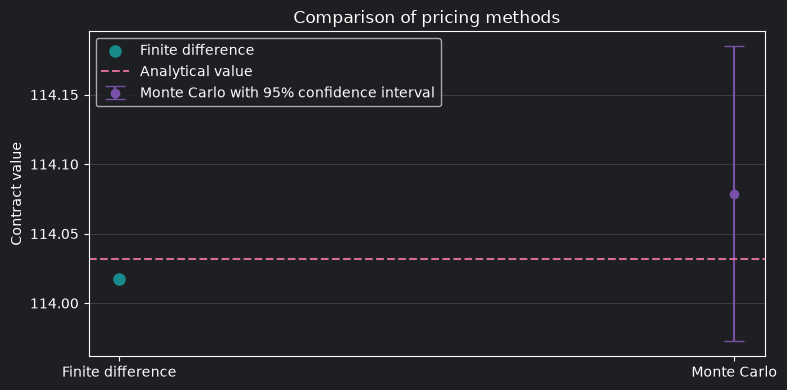

In [32]:
# Part (d): Monte Carlo simulation

n_simulations = 200_000
rng = np.random.default_rng(42)

# Independent normal samples for the two stocks
Z1 = rng.standard_normal(n_simulations)
Z2 = rng.standard_normal(n_simulations)

# Exact terminal stock prices
S1_T = S1 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z1
)

S2_T = S2 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z2
)

discounted_payoffs = np.exp(-r * T) * np.maximum(S1_T, S2_T)

mc_price = discounted_payoffs.mean()
mc_se = discounted_payoffs.std(ddof=1) / np.sqrt(n_simulations)

ci_lower = mc_price - 1.96 * mc_se
ci_upper = mc_price + 1.96 * mc_se

print(f"Analytical price: {analytical_price:.6f}")
print(f"FDM price:        {fdm_price:.6f}")
print(f"Monte Carlo:      {mc_price:.6f}")
print()
print(f"FDM absolute error: {abs(fdm_price - analytical_price):.6f}")
print(f"MC absolute error:  {abs(mc_price - analytical_price):.6f}")
print(f"MC standard error:  {mc_se:.6f}")
print(f"MC 95% interval:    [{ci_lower:.6f}, {ci_upper:.6f}]")
print(
    "Analytical price inside interval:",
    ci_lower <= analytical_price <= ci_upper
)

# Compare numerical prices with the analytical benchmark
fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(
    0, fdm_price, color="#178B8B", s=65,
    label="Finite difference", zorder=3
)

ax.errorbar(
    1, mc_price, yerr=1.96 * mc_se,
    fmt="o", color="#7851A9", capsize=7,
    label="Monte Carlo with 95% confidence interval"
)

ax.axhline(
    analytical_price, color="#D76A99",
    linestyle="--", label="Analytical value"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Finite difference", "Monte Carlo"])
ax.set_ylabel("Contract value")
ax.set_title("Comparison of pricing methods")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Results and conclusion

I priced the contract using the analytical formula, finite
differences and Monte Carlo simulation.

Using 200,000 simulations, I obtained a Monte Carlo standard error
of 0.054161 and an approximate 95% confidence interval of
[113.972610, 114.184922].

Both the analytical price and the finite difference price lie
inside this interval. The observed Monte Carlo error is less
than one standard error, so the difference is consistent with
sampling uncertainty.

In my grid-refinement experiment, the finite difference error
decreased as I reduced the stock-price spacing and time step.
The PDE calculation still includes discretization error and
approximation at the upper boundaries.

For this grid and simulation sample, finite differences produced
a smaller absolute error than Monte Carlo. This does not imply
that finite differences are always more accurate.

Overall, both numerical methods give results close to the
analytical benchmark for my chosen parameters:
$S_1(0)=S_2(0)=100$, $\sigma=0.25$, $r=0.03$ and $T=1$.